# 61 · 고정 데이터·보수적 Q·오프라인 정책 평가

📎 **이번 질문** · 이미 모은 기록만 있을 때, 어떤 행동을 학습하고 어떤 정책을 평가할 수 있을까요?

준비물: 27 중요도 추정, 52 Bellman, 54 행동 확률, 55 Q-learning, 59 off-policy, 03·04 MLP·Adam. NumPy·CPU float64만 사용하며 다른 노트북 실행 상태나 다운로드에 의존하지 않습니다. 다섯 위치·다섯 힘의 유한 제어 환경로 수식부터 실제 학습까지 연결합니다.

| 표시 | 뜻 | 읽는 법 |
|---|---|---|
| 🔑 | 핵심 | 축과 기울기 경로를 씁니다 |
| 🔍 | 확인 | 그림·손계산·독립 평가를 대조합니다 |
| 📎 | 참고 | 처음 나온 용어·관용구를 풀이합니다 |
| ✏️ | 연습 | 한두 줄을 채우고 검사합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 고정 자료의 관측 횟수와 행동분포의 support를 구분합니다.
2. 보수적 Q 손실을 전체 미분하고 새 환경 상호작용 없이 실제로 학습합니다.
3. IS·WIS 평가의 분모·support·분산을 확인하며 다른 정책의 결과로 원래 정책을 대신 평가하지 않습니다.

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/offline_rl_plots.py)

In [1]:
# 준비 셀: 그림과 독립 미분 검산 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient,rel_error
from src.utils.offline_rl_plots import plot_panels,plot_curves
setup_plots()

'Arial Unicode MS'

## 🔑 1. 기록에 없는 행동은 어떻게 다뤄야 할까요?

**이 절에서 가져갈 것:** 고정 자료의 빈칸과 참 행동확률이 0인 칸을 구분합니다.

장치를 원점으로 옮긴 과거 기록만 받았습니다. 더 큰 힘을 쓰면 잘될 것처럼 보여도 새 실험으로 확인할 수 없습니다. 59번의 replay는 계속 새 경험을 보충했지만 여기서는 학습 시작 전에 자료를 고정합니다.

> **용어**
> - **오프라인 RL**은 주어진 고정 전이 자료로 정책을 학습하며 학습 중 새 환경 상호작용을 하지 않습니다.
> - **행동 정책(behavior policy) μ**는 기록을 만든 정책이고, **평가 정책 π**는 반환을 알고 싶은 정책입니다.
> - **support(지원 범위)**는 확률이 양수인 행동들의 범위입니다. **coverage**는 자료가 상태·행동 범위를 얼마나 포함하는지 뜻하며 여기서는 관측 횟수와 μ>0를 따로 표시합니다.

위치 s와 힘 a는 모두 {−2,−1,0,1,2}입니다. 인덱스 i,j=0…4로 저장하며 값은 i−2,j−2입니다. $i'=\operatorname{clip}(i+j-2,0,4)$, $r=-[(i'-2)^2+.1(j-2)^2]$. 시작 위치는 다섯 값 균일, γ=.9이며 **4번째 전이 뒤 실제 종료**합니다. 남은 시간이 다르면 가치도 달라지므로 상태는 (t,i), t=0…3으로 둡니다.

좁은 μ는 원점 쪽 한 칸 또는 정지만 사용하며, 원점에서는 ±1도 각각 .15로 사용합니다. 넓은 μ는 다섯 힘을 각각 .2로 사용합니다. μ:(S,A)=(5,5), 기록 states:(N,5), actions/rewards/probabilities:(N,4)입니다. 이 예제에서는 실제 logging 확률을 알고 함께 저장합니다. 실제 기록에서 μ를 추정하면 그 오차도 추가됩니다.

> **코드** · `cumsum(axis=1)`은 행동의 누적확률입니다. `u >= 누적확률`의 참 개수를 행동 인덱스로 쓰면 u=0에서도 선두 확률0을 건너뜁니다. `np.add.at`은 같은 (상태,행동)에 여러 표본이 오면 빠짐없이 누적합니다.

In [2]:
demo_mu=np.zeros((5,5))
for i in range(5):
    demo_mu[i,2]=.3
    demo_mu[i,3 if i<2 else 1]=.7
demo_mu[2]=[0.,.15,.7,.15,0.]
demo_wide=np.full((5,5),.2)
demo_state=np.array([0,0,2,4])
demo_action=np.array([3,2,2,1])
demo_count=np.zeros((5,5),dtype=int)
for i,j in zip(demo_state,demo_action):
    demo_count[i,j]+=1

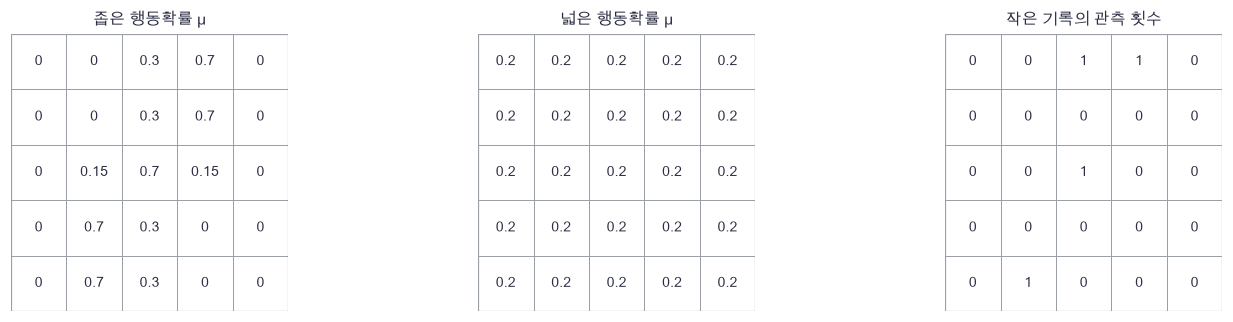

In [3]:
plot_panels([demo_mu,demo_wide,demo_count],['좁은 행동확률 μ','넓은 행동확률 μ','작은 기록의 관측 횟수'])

🔍 **확인** · 행은 위치, 열은 힘의 인덱스입니다. 확률이 양수여도 작은 기록에서는 한 번도 관측되지 않을 수 있습니다. 반면 μ=0인 행동은 기록을 더 많이 모아도 같은 행동 정책 아래에서는 나타나지 않습니다.

In [4]:
def grid_step(state,action):
    """인덱스0–4를 위치/힘−2–2로 읽는 결정론 전이와 음의 비용입니다."""
    next_state=np.clip(state+action-2,0,4)
    reward=-((next_state-2.)**2+.1*(action-2.)**2)
    return next_state.astype(int),reward

In [5]:
def behavior_policy(wide=False):
    """좁은 정책은 원점 방향 한 칸 또는정지, 넓은 정책은 다섯 힘 모두를 씁니다."""
    if wide:
        return np.full((5,5),.2)
    mu=np.zeros((5,5))
    for s in range(5):
        mu[s,2]=.3
        mu[s,3 if s<2 else 1]=.7
    mu[2]=np.array([0.,.15,.7,.15,0.])
    return mu

In [6]:
def collect_logged(mu,episodes,seed):
    """고정4step episode와 실제 행동확률을 기록합니다. 학습 도중 추가하지 않습니다."""
    rng=np.random.default_rng(seed)
    states=np.zeros((episodes,5),dtype=int)
    states[:,0]=rng.integers(0,5,episodes)
    actions=np.zeros((episodes,4),dtype=int)
    rewards=np.zeros((episodes,4))
    probabilities=np.zeros((episodes,4))
    for t in range(4):
        probs=mu[states[:,t]]
        uniforms=rng.random(episodes)
        action=(uniforms[:,None]>=np.cumsum(probs,axis=1)).sum(axis=1)
        states[:,t+1],rewards[:,t]=grid_step(states[:,t],action)
        actions[:,t]=action
        probabilities[:,t]=probs[np.arange(episodes),action]
    return {'states':states,'actions':actions,'rewards':rewards,'probabilities':probabilities}

In [7]:
def state_features(time,state):
    """시간0–3과 위치0–4를 묶은20차원 one-hot입니다."""
    return np.eye(20)[5*time+state]

In [8]:
def offline_arrays(data):
    """episode 자료를 고정 transition 배열로 펼칩니다. 마지막 시각만 실제 종료입니다."""
    n=len(data['actions'])
    times=np.tile(np.arange(4),n)
    states=data['states'][:,:4].reshape(-1)
    next_states=data['states'][:,1:].reshape(-1)
    X=state_features(times,states)
    next_X=state_features(np.minimum(times+1,3),next_states)
    return X,data['actions'].reshape(-1),data['rewards'].reshape(-1),next_X,(times==3).astype(float)

In [9]:
# 쓰는 것: behavior_policy (1절) · demo_action (1절) · demo_count (1절) · demo_mu (1절) · demo_state (1절)
np.testing.assert_allclose(behavior_policy(),demo_mu)  # 검산: 직접 구성한 확률과 함수 일치
vector_count=np.zeros((5,5),dtype=int)
np.add.at(vector_count,(demo_state,demo_action),1)
np.testing.assert_array_equal(vector_count,demo_count)  # 검산: 반복문 = 중복 누적 벡터화
np.testing.assert_array_equal(vector_count[[0,0,2,4],[3,2,2,1]],[1,1,1,1])  # 검산: 손계산 네 칸
u_zero=np.zeros((5,1))
first_positive=(u_zero>=np.cumsum(demo_mu,axis=1)).sum(axis=1)
assert np.all(demo_mu[np.arange(5),first_positive]>0), 'u=0도 확률0 행동을 고르면 안 됩니다'
np.testing.assert_array_equal(first_positive,[2,2,1,1,1])  # 검산: 각 행 첫 양의확률 행동
mini_data=collect_logged(demo_mu,3,6100)
mini_X,mini_A,mini_R,mini_NX,mini_done=offline_arrays(mini_data)
np.testing.assert_array_equal(mini_done.reshape(3,4),np.tile([0.,0.,0.,1.],(3,1)))  # 검산: 실제 종료 시각
assert mini_X.shape==(12,20), '시간·위치 one-hot은20좌표입니다'
np.testing.assert_array_equal(state_features(np.array([0,1]),np.array([2,2])).argmax(axis=1),[2,7])  # 검산: 같은위치 다른시간

### ✏️ 연습 1 · 관측 횟수와 support

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

확률은 양수지만 현재 기록에서 관측하지 못한 칸을 표시하세요.

In [10]:
def exercise_observed_count(counts,mu):
    """확률은 양수지만 현재 기록에서 관측하지 못한 칸을 표시하세요."""

    ### 구현할 내용: 확률은 양수지만 현재 기록에서 관측하지 못한 칸을 표시하세요.
    raise NotImplementedError
    return missing

In [11]:
def check_observed_count(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.array([[0,2,0]]),np.array([[.5,.5,0.]])),[[True,False,False]])  # 검산: 관측없지만가능한 첫칸만
    print("연습 1: 독립 기준값과 일치합니다.")

run_check(check_observed_count,exercise_observed_count,hint="확률은 양수지만 현재 기록에서 관측하지 못한 칸을 표시하세요.")

☐ exercise_observed_count: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 확률은 양수지만 현재 기록에서 관측하지 못한 칸을 표시하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
missing = (counts==0)&(mu>0)
```

</details>

## 🔑 2. 다른 정책의 반환을 기록에서 추정합니다

**이 절에서 가져갈 것:** 중요도비의 분모는 실제 logging 확률이며 support 위반은 평가 불가입니다.

평가 정책이 자주 고르는 행동이 과거에는 드물었다면, 그런 기록에 더 큰 가중치를 줍니다. 길이4 궤적 n의 반환과 가중치는
$$G_n=\sum_{t=0}^{3}\gamma^t r_{nt},\quad w_n=\prod_{t=0}^{3}\frac{\pi_t(a_{nt}|s_{nt})}{\mu(a_{nt}|s_{nt})}.$$
$$\hat J_{IS}=\frac1N\sum_n w_nG_n,\qquad \hat J_{WIS}=\frac{\sum_n w_nG_n}{\sum_n w_n},\qquad ESS=\frac{(\sum_n w_n)^2}{\sum_n w_n^2}.$$

> **용어** · **오프라인 정책 평가(OPE)**는 다른 정책이 만든 기록으로 새 정책의 반환을 추정합니다. **IS**는 중요도 가중 표본평균, **WIS**는 가중치 합으로 다시 나눈 추정입니다. **ESS**는 가중치가 고르게 퍼졌는지 보는 유효 표본 수 진단입니다.

두 정책의 시작분포와 환경은 같습니다. support와 정확한 μ, 독립 episode 등 조건 아래 IS는 불편 추정이지만 궤적 확률비 곱 때문에 분산이 커질 수 있습니다. WIS는 유한 표본에서 일반적으로 편향되며 반드시 더 정확하지는 않습니다. 여기서는 clipping이나 확률 바닥값으로 추정 대상을 바꾸지 않습니다.

π>0인데 μ=0인 곳은 기록으로 중요도 평가할 수 없습니다. `assert_support`는 **모든 시각·상태**를 검사하는 강한 충분조건입니다. 평가 정책에서 실제 도달할 수 있는 상태만 따지는 최소 조건보다 보수적입니다. 정책을 μ의 support 안으로 제한하면 평가할 수 있지만 그것은 **새 정책**입니다. 원래 정책의 값으로 보고하지 않습니다.

IS의 표준오차는 독립 episode 기여값 $w_nG_n$의 표본표준편차/√N입니다. 고정된 학습 정책에 조건부인 표본 불확실성 진단이며 정규근사 신뢰구간의 정확성이나 학습 seed 변동까지 보장하지 않습니다. 모든 w=0이면 WIS는 정의되지 않습니다. 그때 관측 IS·SE=0도 참 반환이0이라는 증거가 아닙니다.

> **코드** · `policy[times,states,actions]`는 각 기록의 시각·상태·행동 확률을 고릅니다. `prod(axis=1)`은 시간축의 비를 곱합니다. `std(ddof=1)`은 episode 표본분산 분모 N−1을 사용합니다.

In [12]:
hand_weights=np.array([2.,0.])
hand_returns=np.array([-1.,-3.])
hand_contribution=hand_weights*hand_returns
hand_summary=np.array([hand_contribution.mean(),hand_contribution.sum()/hand_weights.sum(),
                       hand_weights.sum()**2/(hand_weights**2).sum(),
                       hand_contribution.std(ddof=1)/np.sqrt(2)])

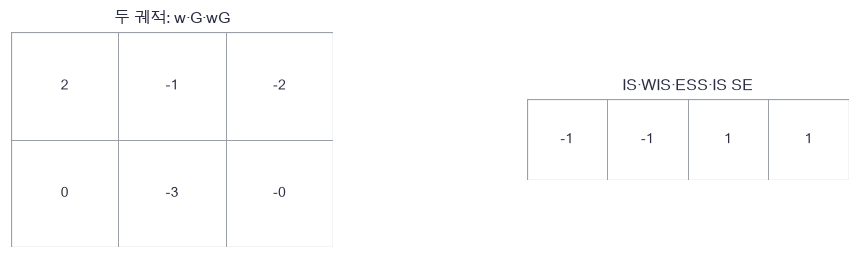

In [13]:
plot_panels([np.column_stack([hand_weights,hand_returns,hand_contribution]),hand_summary[None,:]],['두 궤적: w·G·wG','IS·WIS·ESS·IS SE'])

🔍 **확인** · 두 기록 중 첫 기록만 기여합니다. IS=−1, WIS=−1, ESS=1입니다. ESS는 독립 표본을 새로 만든 숫자가 아니라 가중치의 집중도 진단입니다.

In [14]:
def assert_support(policy,mu):
    """정책이 μ=0인 행동을 쓰면 데이터만의 중요도 평가를 거부합니다."""
    if np.any((policy>0)&(mu[None,:,:]==0)):
        raise ValueError('평가 정책이 행동분포의 support 밖을 사용합니다')

In [15]:
def importance_summary(weights,returns):
    """trajectory IS·WIS·ESS·조건부IS SE. 모든weight0이면 WIS는정의하지 않습니다."""
    contribution=weights*returns
    estimate=contribution.mean()
    se=contribution.std(ddof=1)/np.sqrt(len(returns))
    total=weights.sum()
    if total==0:
        return np.array([estimate,np.nan,0.,se])
    wis=contribution.sum()/total
    ess=total**2/(weights**2).sum()
    return np.array([estimate,wis,ess,se])

In [16]:
def evaluate_logged(data,policy,mu):
    """독립 logged episode의 전체 trajectory 중요도비로 IS·WIS를 계산합니다."""
    assert_support(policy,mu)  # 검산: 지원 범위 위반이면 추정을 거부합니다
    times=np.arange(4)[None,:]
    numerator=policy[times,data['states'][:,:4],data['actions']]
    ratios=numerator/data['probabilities']
    weights=ratios.prod(axis=1)
    returns=(data['rewards']*(.9**np.arange(4))).sum(axis=1)
    return importance_summary(weights,returns),weights

In [17]:
# 쓰는 것: demo_mu (1절) · hand_returns (2절) · hand_summary (2절) · hand_weights (2절) · mini_data (1절)
np.testing.assert_allclose(importance_summary(hand_weights,hand_returns),[-1.,-1.,1.,1.])  # 검산: 손계산
loop_is=0.
for weight,ret in zip(hand_weights,hand_returns):
    loop_is+=weight*ret/len(hand_returns)
np.testing.assert_allclose(loop_is,hand_summary[0])  # 검산: 반복문 = 벡터화
on_policy=np.broadcast_to(demo_mu,(4,5,5)).copy()
on_stats,on_weights=evaluate_logged(mini_data,on_policy,demo_mu)
np.testing.assert_allclose(on_weights,np.ones(3))  # 검산: π=μ이면 비율 모두1
np.testing.assert_allclose(on_stats[:2],np.repeat((mini_data['rewards']*.9**np.arange(4)).sum(axis=1).mean(),2))  # 검산: 원래 반환평균
zero_stats=importance_summary(np.zeros(2),hand_returns)
assert np.isnan(zero_stats[1]) and zero_stats[2]==0, '모든 가중치0이면 WIS 미정의·ESS0입니다'
bad_policy=on_policy.copy()
bad_policy[0,0]=[1.,0.,0.,0.,0.]
try:
    evaluate_logged(mini_data,bad_policy,demo_mu)
except ValueError:
    print('support 밖 정책의 OPE를 의도대로 거부했습니다.')
else:
    raise AssertionError('확률0 분모의 정책을 평가하면 안 됩니다')

support 밖 정책의 OPE를 의도대로 거부했습니다.


### ✏️ 연습 2 · 전체 궤적 중요도비

기록한 행동의 확률비를 시간축으로 곱하세요. 분모는 모두 양수라고 가정합니다.

In [18]:
def exercise_trajectory_weight(target_probability,logged_probability):
    """기록한 행동의 확률비를 시간축으로 곱하세요. 분모는 모두 양수라고 가정합니다."""

    ### 구현할 내용: 기록한 행동의 확률비를 시간축으로 곱하세요. 분모는 모두 양수라고 가정합니다.
    raise NotImplementedError
    return weights

In [19]:
def check_trajectory_weight(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[.4,.5],[0.,.2]]),np.array([[.2,.5],[.3,.4]])),[2.,0.])  # 검산: 두시각 비율곱
    print("연습 2: 독립 기준값과 일치합니다.")

run_check(check_trajectory_weight,exercise_trajectory_weight,hint="기록한 행동의 확률비를 시간축으로 곱하세요. 분모는 모두 양수라고 가정합니다.")

☐ exercise_trajectory_weight: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 기록한 행동의 확률비를 시간축으로 곱하세요. 분모는 모두 양수라고 가정합니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
weights = (target_probability/logged_probability).prod(axis=1)
```

</details>

## 🔑 3. 관측 행동의 Bellman 오차와 보수적 벌점을 미분합니다

**이 절에서 가져갈 것:** 기록에 없는 행동의 높은 Q를 그대로 믿지 않도록 상대적 값을 조정합니다.

관측한 행동만 TD로 맞추면 다른 행동의 Q는 직접 정답을 보지 못합니다. max Q가 그런 행동을 선택하면 bootstrap 목표도 잘못 커질 수 있습니다.

> **용어** · **CQL(Conservative Q-Learning)**은 자료의 행동에 비해 다른 행동의 Q가 과도하게 커지는 것을 억제하는 목적을 추가합니다. 여기서는 작은 이산 행동의 logsumexp 벌점을 사용합니다. **logsumexp**는 $\log\sum_a e^{Q_a}$이며 최댓값을 빼서 안정적으로 계산합니다.

시간·위치 one-hot $X:(B,20)$을 $H=\tanh(XW+b)$, $Q=HV+c$로 보냅니다. 은닉16, 출력5이고 별도 actor 없이 argmax Q로 정책을 얻습니다. 고정 target 사본을 $\bar Q$라 하면
$$y_n=r_n+.9(1-d_n)\max_a\bar Q(x'_n,a),\quad L=\frac1{2B}\sum_n(Q_{n,a_n}-y_n)^2+\frac\alpha B\sum_n[\log\sum_a e^{Q_{na}}-Q_{n,a_n}].$$
$y$는 이 미분에서 상수입니다. $P=\operatorname{softmax}(Q)$, $\delta=Q_{n,a_n}-y_n$이면
$$G_{na}=\frac1B[\delta_n\mathbf1(a=a_n)+\alpha(P_{na}-\mathbf1(a=a_n))].$$
$dV=H^TG$, $dc=\sum G$, $dU=(GV^T)\odot(1-H^2)$, $dW=X^TdU$, $db=\sum dU$, $dX=dUW^T$입니다. 모든 배열과 입력을 중심차분합니다. one-hot 입력의 연속 미분은 구현 검산이며 실제 범주형 상태를 미분한다는 뜻은 아닙니다.

벌점은 같은 상태의 Q 전체에 같은 상수를 더해도 변하지 않습니다. 모든 Q를 무조건 낮추는 항이 아니라 자료 행동과의 **상대적 차이**를 바꿉니다. α=0은 일반 TD입니다. 원 논문의 조건부 하한 정리를 이 유한 MLP·유한 갱신 결과의 모든 상태·행동 하한 보장으로 사용하지 않습니다.

In [20]:
demo_Q=np.array([[0.,np.log(2),0.],[np.log(3),0.,0.]])
demo_A=np.array([1,0])
demo_P=np.exp(demo_Q)/np.exp(demo_Q).sum(axis=1,keepdims=True)
demo_penalty=np.log(np.exp(demo_Q).sum(axis=1))-demo_Q[np.arange(2),demo_A]
demo_G=.5*demo_P/2
demo_G[np.arange(2),demo_A]-=.5/2

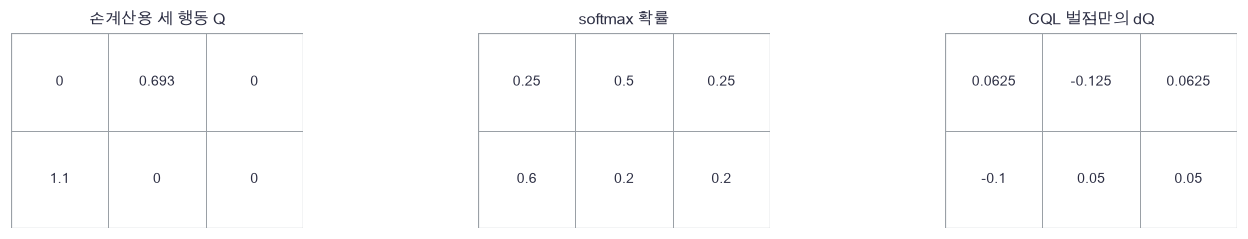

In [21]:
plot_panels([demo_Q,demo_P,demo_G],['손계산용 세 행동 Q','softmax 확률','CQL 벌점만의 dQ'])

🔍 **확인** · 관측 행동의 벌점 기울기는 음수이고 나머지는 양수입니다. 경사하강은 관측 행동을 상대적으로 높입니다. 이 그림은 세 행동의 손계산용이고 실제 모델 출력은 다섯 행동입니다.

In [22]:
def init_mlp(din,dout,seed,hidden=8):
    """tanh 은닉층 하나와 선형 출력층의 모든 배열을 초기화합니다."""
    rng=np.random.default_rng(seed)
    return {'W':rng.normal(0,.3,(din,hidden)),'b':np.zeros(hidden),
            'V':rng.normal(0,.15,(hidden,dout)),'c':np.zeros(dout)}

In [23]:
def mlp_forward(X,p):
    """H=tanh(XW+b), Y=HV+c. 입력:(N,D) → 출력:(N,K),cache."""
    H=np.tanh(X@p['W']+p['b'])
    return H@p['V']+p['c'],(X,H)

In [24]:
def mlp_backward(G,cache,p):
    """모든 파라미터·입력의 연쇄법칙입니다. G는 출력과 같은 shape입니다."""
    X,H=cache
    dU=(G@p['V'].T)*(1-H**2)
    grads={'V':H.T@G,'c':G.sum(axis=0),'W':X.T@dU,'b':dU.sum(axis=0)}
    return grads,dU@p['W'].T

In [25]:
def conservative_loss(X,actions,target,p,alpha=.5):
    """Bellman 반 MSE + α(logsumexp Q−Qdata)의 전체 파라미터·입력 미분입니다."""
    Q,cache=mlp_forward(X,p)
    row=np.arange(len(X))
    chosen=Q[row,actions]
    residual=chosen-target
    shifted=Q-Q.max(axis=1,keepdims=True)
    expQ=np.exp(shifted)
    probability=expQ/expQ.sum(axis=1,keepdims=True)
    logsum=Q.max(axis=1)+np.log(expQ.sum(axis=1))
    conservative=np.mean(logsum-chosen)
    G=alpha*probability/len(X)
    G[row,actions]+= (residual-alpha)/len(X)
    grads,dX=mlp_backward(G,cache,p)
    td=.5*np.mean(residual**2)
    return td+alpha*conservative,grads,dX,np.array([td,conservative])

In [26]:
# 쓰는 것: demo_A (3절) · demo_G (3절) · demo_Q (3절) · demo_penalty (3절) · init_mlp (3절)
np.testing.assert_allclose(demo_penalty,[np.log(2),np.log(5/3)])  # 검산: log4−log2, log5−log3
np.testing.assert_allclose(demo_G.sum(axis=1),np.zeros(2),atol=1e-15)  # 검산: 공통 이동의 미분0
shifted_penalty=np.log(np.exp(demo_Q+2).sum(axis=1))-(demo_Q+2)[np.arange(2),demo_A]
np.testing.assert_allclose(shifted_penalty,demo_penalty)  # 검산: Q공통이동 불변
terminal_y=np.array([-1.,-2.])+.9*(1-np.array([0.,1.]))*np.array([5.,100.])
np.testing.assert_allclose(terminal_y,[3.5,-2.])  # 검산: 종료는 bootstrap 제거
probe=init_mlp(20,5,6119,3)
probe_x=np.array([np.linspace(-.2,.3,20),np.linspace(.4,-.1,20)])
probe_a=np.array([1,4])
probe_y=np.array([-.3,.1])
_,analytic,analytic_x,_=conservative_loss(probe_x,probe_a,probe_y,probe,.5)

In [27]:
def cql_objective():
    """target을 고정한 전체 TD+CQL 목적의 중심차분입니다."""
    return conservative_loss(probe_x,probe_a,probe_y,probe,.5)[0]

In [28]:
gradient_errors=[]
for key in probe:
    numeric=numerical_gradient(cql_objective,probe[key])
    np.testing.assert_allclose(analytic[key],numeric,atol=2e-8)  # 검산: 전체 파라미터 미분
    gradient_errors.append(np.max(np.abs(analytic[key]-numeric)))
numeric_x=numerical_gradient(cql_objective,probe_x)
np.testing.assert_allclose(analytic_x,numeric_x,atol=2e-8)  # 검산: 전체 입력 미분
print('전체 중심차분 최대 절대오차',max(*gradient_errors,np.max(np.abs(analytic_x-numeric_x))))

전체 중심차분 최대 절대오차 1.0944191169634521e-10


### ✏️ 연습 3 · 벌점의 행동별 기울기

CQL 벌점만의 기울기에서 자료 행동의 항을 빼세요.

In [29]:
def exercise_conservative_gradient(probability,actions,alpha):
    """CQL 벌점만의 기울기에서 자료 행동의 항을 빼세요."""
    G = alpha*probability/len(actions)
    ### 구현할 내용: CQL 벌점만의 기울기에서 자료 행동의 항을 빼세요.
    raise NotImplementedError
    return G

In [30]:
def check_conservative_gradient(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[.2,.8]]),np.array([1]),.5),[[.1,-.1]])  # 검산: 한관측 두행동
    print("연습 3: 독립 기준값과 일치합니다.")

run_check(check_conservative_gradient,exercise_conservative_gradient,hint="CQL 벌점만의 기울기에서 자료 행동의 항을 빼세요.")

☐ exercise_conservative_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: CQL 벌점만의 기울기에서 자료 행동의 항을 빼세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
G[np.arange(len(actions)),actions] -= alpha/len(actions)
```

</details>

## 🔑 4. 고정 자료에서 네 모델을 끝까지 학습합니다

**이 절에서 가져갈 것:** 수집과 학습을 분리하고 동일한 초기화·갱신 예산으로 비교합니다.

좁은·넓은 μ에서 각각 train256episode=1024전이를 수집합니다(seed6101/6102). 별도 validation128episode(seed6105/6106), test1024episode(seed6103/6104)도 미리 만듭니다. 학습 함수는 train만 받습니다. validation은 종료 후 Bellman 일관성을 관찰하며 모델을 고르지 않습니다. 최종 OPE는 test만 사용합니다.

각 자료에서 α=0/.5를 각각 학습합니다. 공통 초기seed6110, batchseed6111, 은닉16, 600갱신·batch64·Adam lr.003,20갱신마다 target을 완전 복사합니다. Adam은 .9/.999 모멘트·bias 보정·epsilon1e−8을 사용합니다. 같은 자료의 두 α는 같은 복원추출 인덱스를 사용합니다. 다른 μ의 같은 인덱스는 같은 전이가 아닙니다. 한 초기seed의 교육용 비교이며 α·갱신수를 결과 후 바꾸지 않습니다.

별도 분산 감사도 미리 고정합니다: 학습과 무관한 같은 정책을 좁은·넓은 μ의64episode 기록으로 각각20회 평가(seed6200…6219/6300…6319). 이 추가 기록은 시뮬레이터에서 OPE의 반복 변동을 확인하는 **감사용 자료**이며 학습에 합치지 않습니다. 실제 오프라인 작업에서 이런 새 기록을 얻을 수 있다고 가정하지 않습니다.

> **코드** · `integers(0,N,64)`는 복원추출 배치입니다. 사전 배열마다 `.copy()`하여 target이 online 배열과 메모리를 공유하지 않게 합니다. `np.where(mu>0,Q,-np.inf)`는 다음 절에서 support 밖 행동을 선택 후보에서 제외합니다.

In [31]:
# 쓰는 것: behavior_policy (1절) · collect_logged (1절)
mus=[behavior_policy(False),behavior_policy(True)]
train_logs=[collect_logged(mu,256,6101+i) for i,mu in enumerate(mus)]
valid_logs=[collect_logged(mu,128,6105+i) for i,mu in enumerate(mus)]
test_logs=[collect_logged(mu,1024,6103+i) for i,mu in enumerate(mus)]
fixed_train=[{k:v.copy() for k,v in data.items()} for data in train_logs]
coverage=[]
for data in train_logs:
    count=np.zeros((5,5),dtype=int)
    np.add.at(count,(data['states'][:,:4].reshape(-1),data['actions'].reshape(-1)),1)
    coverage.append(count)
budget=np.array([[256,1024,600,64],[256,1024,600,64]])

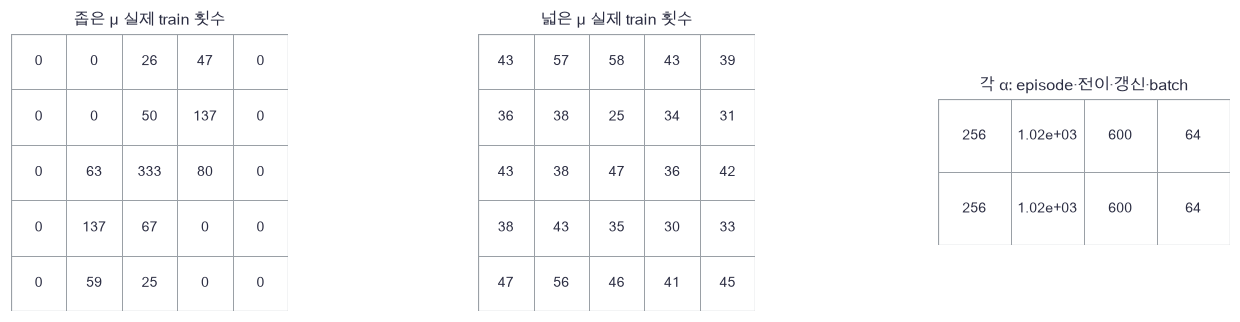

In [32]:
plot_panels(coverage+[budget],['좁은 μ 실제 train 횟수','넓은 μ 실제 train 횟수','각 α: episode·전이·갱신·batch'])

🔍 **확인** · 횟수 표는 시간을 합친5×5표입니다. 모델 입력의20개 시간·위치 상태 각각을 모두 같은 횟수로 보았다는 뜻은 아닙니다. 두 자료의 episode 수는 같아도 행동 범위와 방문 분포는 다릅니다.

In [33]:
def adam_step(p,g,m,v,step,lr=.001):
    """Adam .9/.999 모멘트와 bias 보정으로 배열을 갱신합니다."""
    for key in p:
        m[key]=.9*m[key]+.1*g[key]
        v[key]=.999*v[key]+.001*g[key]**2
        p[key]-=lr*(m[key]/(1-.9**step))/(np.sqrt(v[key]/(1-.999**step))+1e-8)

In [34]:
def copy_parameters(p):
    """각 배열의 독립 사본을 만듭니다."""
    return {key:value.copy() for key,value in p.items()}

In [35]:
def zero_state(p):
    """파라미터와 같은 shape의 optimizer의 0 상태를 만듭니다."""
    return {key:np.zeros_like(value) for key,value in p.items()}

In [36]:
def train_offline(data,alpha,seed=6110):
    """고정1024전이에서만600회 학습하고20갱신마다 target을복사합니다."""
    # 쓰는 것: conservative_loss (3절) · init_mlp (3절) · mlp_forward (3절) · offline_arrays (1절)
    p=init_mlp(20,5,seed,16)
    target=copy_parameters(p)
    m,v=zero_state(p),zero_state(p)
    X,A,R,NX,terminal=offline_arrays(data)
    rng=np.random.default_rng(seed+1)
    history=[]
    for step in range(1,601):
        idx=rng.integers(0,len(X),64)
        next_q,_=mlp_forward(NX[idx],target)
        fixed_y=R[idx]+.9*(1-terminal[idx])*next_q.max(axis=1)
        loss,g,_,terms=conservative_loss(X[idx],A[idx],fixed_y,p,alpha)
        adam_step(p,g,m,v,step,lr=.003)
        if step%20==0:
            target=copy_parameters(p)
        if step%60==0:
            history.append([step,*terms])
    return p,np.array(history)

In [37]:
def q_table(p):
    """전체 시간·위치의Q를 관찰용 표 (4,5,5)로 만듭니다."""
    # 쓰는 것: mlp_forward (3절)
    Q,_=mlp_forward(np.eye(20),p)
    return Q.reshape(4,5,5)

In [38]:
def greedy_policy(Q):
    """Q의 최댓값 행동을 고르는 결정론 정책 표입니다. 동률은 첫 인덱스입니다."""
    return np.eye(Q.shape[-1])[Q.argmax(axis=-1)]

In [39]:
def supported_policy(Q,mu):
    """μ>0인 행동 내greedy80%와 μ20%를 섞은 별도 정책입니다."""
    allowed=np.where(mu[None,:,:]>0,Q,-np.inf)
    return .8*greedy_policy(allowed)+.2*mu[None,:,:]

In [40]:
# 쓰는 것: conservative_loss (3절) · fixed_train (4절) · mlp_forward (3절) · offline_arrays (1절) · train_logs (4절) · train_offline (4절) · valid_logs (4절)
settings=[]
models=[]
histories=[]
validation=[]
for i,data in enumerate(train_logs):
    for alpha in [0.,.5]:
        p,history=train_offline(data,alpha)
        settings.append(('좁은' if i==0 else '넓은')+f' μ · α={alpha:g}')
        models.append(p)
        histories.append(history)
        X,A,R,NX,done=offline_arrays(valid_logs[i])
        next_q,_=mlp_forward(NX,p)
        fixed_target=R+.9*(1-done)*next_q.max(axis=1)
        validation.append(conservative_loss(X,A,fixed_target,p,alpha)[3][0])
print('모델별 파라미터 수',[sum(v.size for v in p.values()) for p in models])
print('독립 validation 반 TD MSE',np.round(validation,5))
for data,before in zip(train_logs,fixed_train):
    for key in data:
        np.testing.assert_array_equal(data[key],before[key])  # 검산: 고정자료를 보충·변조하지 않음
print('네 모델의 고정자료 학습을 마쳤습니다.')

모델별 파라미터 수 [421, 421, 421, 421]
독립 validation 반 TD MSE [2.0000e-05 1.5710e-02 8.2460e-02 2.4653e-01]
네 모델의 고정자료 학습을 마쳤습니다.


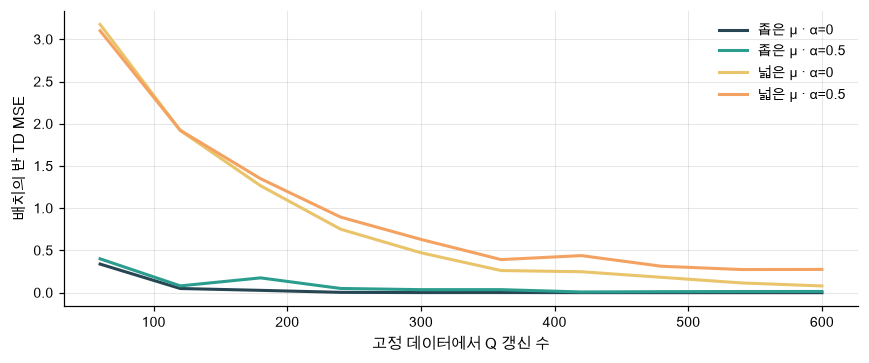

In [41]:
plot_curves([h[:,[0,1]] for h in histories],settings,'배치의 반 TD MSE')

🔍 **확인** · TD 곡선은 바뀌는 target을 맞추는 일관성 진단입니다. 곡선이나 validation TD 오차가 작다는 사실만으로 실제 정책 반환이 좋다고 결론내리지 않습니다. CQL 총손실과 TD 손실은 목적이 다르므로 절대값 순위로 품질을 비교하지 않습니다.

### ✏️ 연습 4 · 실제 종료의 target

종료 indicator가1인 전이는 bootstrap하지 않는 target을 계산하세요.

In [42]:
def exercise_fixed_bellman(reward,done,next_q,gamma):
    """종료 indicator가1인 전이는 bootstrap하지 않는 target을 계산하세요."""

    ### 구현할 내용: 종료 indicator가1인 전이는 bootstrap하지 않는 target을 계산하세요.
    raise NotImplementedError
    return target

In [43]:
def check_fixed_bellman(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([-1.,-2.]),np.array([0.,1.]),np.array([[3.,5.],[100.,200.]]),.9),[3.5,-2.])  # 검산: 종료행은다음Q무시
    print("연습 4: 독립 기준값과 일치합니다.")

run_check(check_fixed_bellman,exercise_fixed_bellman,hint="종료 indicator가1인 전이는 bootstrap하지 않는 target을 계산하세요.")

☐ exercise_fixed_bellman: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 종료 indicator가1인 전이는 bootstrap하지 않는 target을 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
target = reward+gamma*(1-done)*next_q.max(axis=1)
```

</details>

## 🔑 5. 학습 결과와 평가 가능한 정책을 분리합니다

**이 절에서 가져갈 것:** Q의 낙관적 예측, 실제 반환, 지원 범위 안 정책의 OPE를 같은 숫자로 섞지 않습니다.

네 Q로 unrestricted greedy π를 만듭니다. 알려진 작은 시뮬레이터의 **정확한 유한시간 DP**는 감사용입니다:
$$V_4(s)=0,\quad Q_t^\pi(s,a)=r(s,a)+.9V_{t+1}^\pi(s'),\quad V_t^\pi(s)=\sum_a\pi_t(a|s)Q_t^\pi(s,a).$$
초기 다섯 위치 평균 $J(\pi)=\frac15\sum_sV_0^\pi(s)$를 구합니다. 학습이나 정책·α 선택에는 이 참 환경식을 쓰지 않았습니다. 실제 환경을 모르는 오프라인 문제에서는 이런 정확한 반환을 얻을 수 없습니다.

첫 표의 범위 밖 비율은 **20개 시간·위치 격자를 균등하게 센** greedy 행동 중 μ=0 비율입니다. 정책 방문확률로 가중한 비율이 아닙니다. Q 낙관성은 초기 다섯 위치에서 평균 max Q minus 정확한 greedy 반환입니다. 양수는 이 평균에서 과대평가했다는 뜻이지 모든 상태의 오차 부호가 같다는 뜻은 아닙니다.

별도 정책 $\pi_{support}=.8\,\operatorname{greedy}_{\mu>0}(Q)+.2\mu$도 만듭니다. support를 제한하고20% logging 행동을 섞으므로 원래 greedy와 다른 정책입니다. μ가 다르면 이 정책도 달라집니다. 독립 test의 IS/WIS는 **이 새 정책**을 평가합니다. 표에서 참 반환도 별도로 계산해 비교합니다.

In [44]:
# 쓰는 것: greedy_policy (4절) · supported_policy (4절)
illustration_q=np.array([[[3.,1.,2.,0.,4.]]])
illustration_mu=np.array([[0.,.3,.7,0.,0.]])
raw_choice=greedy_policy(illustration_q)
restricted_choice=supported_policy(illustration_q,illustration_mu)
policy_illustration=np.concatenate([illustration_mu,raw_choice[0],restricted_choice[0]],axis=0)

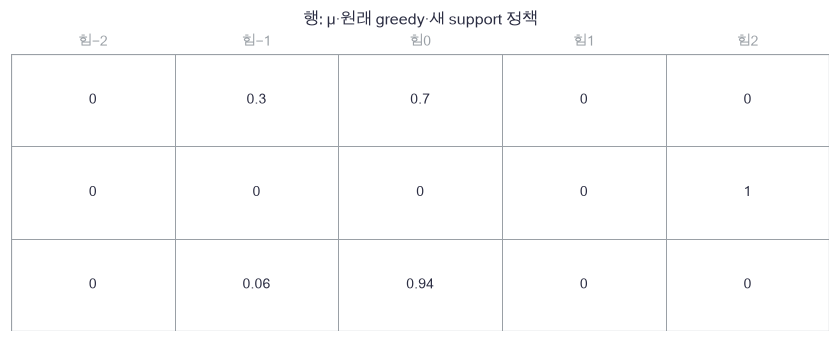

In [45]:
plot_panels([policy_illustration],['행: μ·원래 greedy·새 support 정책'],[['힘−2','힘−1','힘0','힘1','힘2']])

🔍 **확인** · 원래 greedy는 힘2에 확률1이지만 기록은 그 행동을 쓰지 않습니다. 새 정책은 힘0에 .94, 힘−1에 .06입니다. 새 정책의 반환이 좋다고 원래 greedy의 반환도 좋았다고 말할 수 없습니다.

In [46]:
def exact_evaluation(policy):
    """알려진 시뮬레이터만의 감사용 유한horizon DP. 학습·정책선택에 쓰지 않습니다."""
    # 쓰는 것: grid_step (1절)
    V=np.zeros((5,5))
    Q=np.zeros((4,5,5))
    for t in range(3,-1,-1):
        for s in range(5):
            next_s,reward=grid_step(s,np.arange(5))
            Q[t,s]=reward+.9*V[t+1,next_s]
            V[t,s]=np.dot(policy[t,s],Q[t,s])
    return V[0].mean(),V,Q

In [47]:
# 쓰는 것: assert_support (2절)
np.testing.assert_allclose(restricted_choice[0,0],[0.,.06,.94,0.,0.])  # 검산: 별도 정책의 확률
assert_support(restricted_choice,illustration_mu)  # 검산: 새 정책은 양의 logging 확률만 사용
stop_policy=np.zeros((4,5,5))
stop_policy[:,:,2]=1.
stop_exact,_,stop_Q=exact_evaluation(stop_policy)
np.testing.assert_allclose(stop_exact,-2*(1+.9+.9**2+.9**3))  # 검산: 초기 위치제곱 평균2·정지4step
np.testing.assert_allclose(stop_Q[-1,2],[-4.4,-1.1,0.,-1.1,-4.4])  # 검산: 마지막 시각은즉시보상뿐
assert np.allclose(restricted_choice.sum(axis=-1),1), '새 정책도 확률합1이어야 합니다'

In [48]:
# 쓰는 것: assert_support (2절) · evaluate_logged (2절) · greedy_policy (4절) · models (4절) · mus (4절) · q_table (4절) · supported_policy (4절) · test_logs (4절)
greedy_audit=[]
supported_audit=[]
refused=[]
for k,p in enumerate(models):
    mu=mus[k//2]
    Q=q_table(p)
    policy=greedy_policy(Q)
    truth,_,_=exact_evaluation(policy)
    outside=np.mean((policy*(mu[None,:,:]==0)).sum(axis=-1))
    optimism=Q[0].max(axis=1).mean()-truth
    greedy_audit.append([truth,outside,optimism])
    try:
        assert_support(policy,mu)  # 검산: 원래 greedy의 OPE 가능 여부
        refused.append(False)
    except ValueError:
        refused.append(True)
    separate=supported_policy(Q,mu)
    separate_truth,_,_=exact_evaluation(separate)
    stats,weights=evaluate_logged(test_logs[k//2],separate,mu)
    supported_audit.append([separate_truth,*stats])

In [49]:
# 쓰는 것: settings (4절)
greedy_audit=np.array(greedy_audit)
supported_audit=np.array(supported_audit)
print('원래 greedy OPE support 검사 거부 여부',dict(zip(settings,refused)))
print('greedy [참반환, 격자밖비율, Q낙관성]',greedy_audit)
print('별도정책 [참반환, IS, WIS, ESS, IS SE]',supported_audit)

원래 greedy OPE support 검사 거부 여부 {'좁은 μ · α=0': True, '좁은 μ · α=0.5': False, '넓은 μ · α=0': False, '넓은 μ · α=0.5': False}
greedy [참반환, 격자밖비율, Q낙관성] [[-8.81560000e+00  6.00000000e-01  8.94095097e+00]
 [-5.16000000e-01  0.00000000e+00  8.24953365e-03]
 [-5.16000000e-01  0.00000000e+00  1.17502908e-01]
 [-5.16000000e-01  0.00000000e+00 -2.09897395e+00]]
별도정책 [참반환, IS, WIS, ESS, IS SE] [[-8.15294945e-01 -8.36573125e-01 -8.74964383e-01  3.80751874e+02
   3.47331722e-02]
 [-8.15294945e-01 -8.36573125e-01 -8.74964383e-01  3.80751874e+02
   3.47331722e-02]
 [-2.09781699e+00 -2.65434978e+00 -1.72569784e+00  8.31799916e+00
   4.64602021e-01]
 [-2.12449731e+00 -2.57298398e+00 -1.69403429e+00  8.11683597e+00
   4.62733596e-01]]


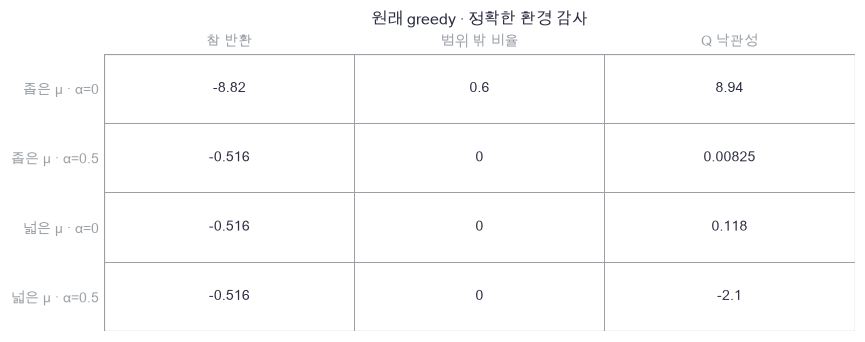

In [50]:
plot_panels([greedy_audit],['원래 greedy · 정확한 환경 감사'],[['참 반환','범위 밖 비율','Q 낙관성']],rows=[settings])

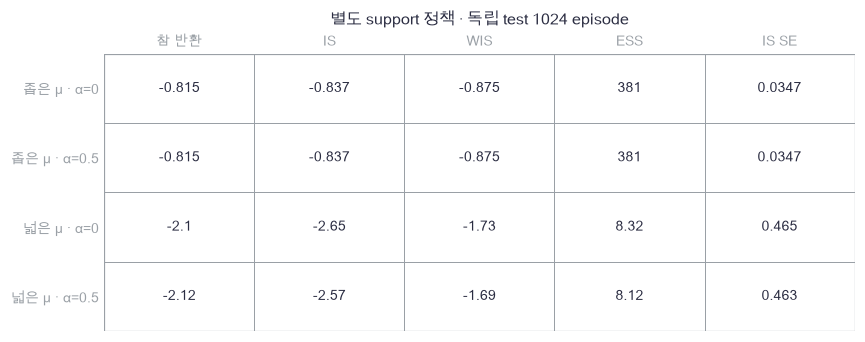

In [51]:
plot_panels([supported_audit],['별도 support 정책 · 독립 test 1024 episode'],[['참 반환','IS','WIS','ESS','IS SE']],rows=[settings])

🔍 **확인** · 이 고정 실험에서 좁은 μ·α0의 greedy는20격자 중60%에서 지원 밖 행동을 고르고 참 반환 약−8.82를 보입니다. α.5의 참 반환은 약−.516입니다. 넓은 μ에서는 두 α의 greedy 반환이 같지만 α.5 Q값은 과소평가됩니다. 이는 이번 초기화·자료의 관찰이며 CQL의 보편적 우위가 아닙니다. 별도 support 정책은 두 좁은 μ 모델에서 우연히 같아 OPE도 같습니다. 넓은 μ에서 support 정책의 ESS는 약8/1024로 매우 작으므로 큰 기록 수만 보고 신뢰하면 안 됩니다.

In [52]:
# 쓰는 것: collect_logged (1절) · evaluate_logged (2절) · exact_evaluation (5절) · mus (4절) · supported_policy (4절)
fixed_Q=np.zeros((4,5,5))
for s in range(5):
    fixed_Q[:,s,3 if s<2 else 1 if s>2 else 2]=1.
fixed_policy=supported_policy(fixed_Q,mus[0])
fixed_value,_,_=exact_evaluation(fixed_policy)
repeat_estimates=[]
for i,mu in enumerate(mus):
    estimates=[]
    for repeat in range(20):
        audit_log=collect_logged(mu,64,6200+100*i+repeat)
        stats,_=evaluate_logged(audit_log,fixed_policy,mu)
        estimates.append(stats)
    repeat_estimates.append(np.array(estimates))
repeat_table=[]
for estimates in repeat_estimates:
    repeat_table.append([estimates[:,0].mean(),estimates[:,0].std(ddof=1),
                         estimates[:,1].mean(),estimates[:,1].std(ddof=1),estimates[:,2].mean()])
repeat_table=np.array(repeat_table)
print('동일한 사전 고정 정책의 정확 반환',fixed_value)
print('반복20회: IS평균·SD, WIS평균·SD, 평균ESS',repeat_table)

동일한 사전 고정 정책의 정확 반환 -0.8152949448192001
반복20회: IS평균·SD, WIS평균·SD, 평균ESS [[-0.83418059  0.16042396 -0.82768689  0.17394566 24.71005104]
 [-1.05839368  2.08119423 -3.1544824   3.17606849  1.61290788]]


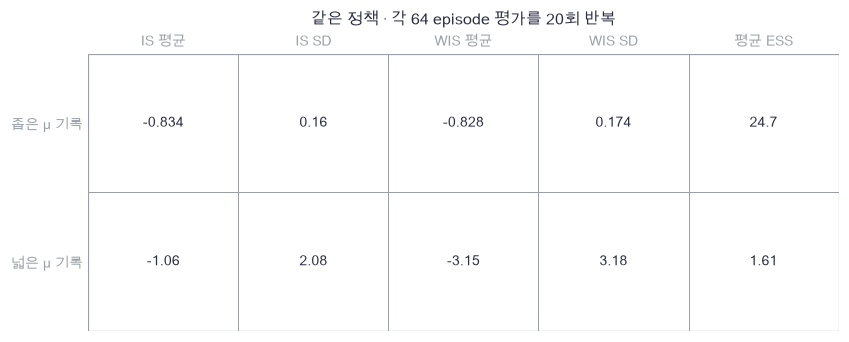

In [53]:
plot_panels([repeat_table],['같은 정책 · 각 64 episode 평가를 20회 반복'],[['IS 평균','IS SD','WIS 평균','WIS SD','평균 ESS']],rows=[['좁은 μ 기록','넓은 μ 기록']])

🔍 **확인** · 이 표는 같은 고정 정책을 평가합니다(참 반환 약−.815). 넓은 μ는 모든 행동을 포함하지만 원하는 궤적과 다르게 행동하는 경우가 많아, 여기서는 IS 반복 표준편차 약2.08·평균ESS 약1.61로 좁은 μ의 약.160·24.7보다 불안정합니다. support의 존재는 낮은 분산까지 보장하지 않습니다. WIS도20회 평균이 참값과 멀 수 있습니다. 반복 SD는20개 독립 기록 집합의 추정 변동이고, 앞 표의 IS SE는 한 기록 집합 내부의 기여값으로 추정한 조건부 불확실성이므로 구분합니다.

### ✏️ 연습 5 · 가중치 집중도

양의 가중치 합을 가정하고 ESS를 계산하세요.

In [54]:
def exercise_effective_size(weights):
    """양의 가중치 합을 가정하고 ESS를 계산하세요."""

    ### 구현할 내용: 양의 가중치 합을 가정하고 ESS를 계산하세요.
    raise NotImplementedError
    return ess

In [55]:
def check_effective_size(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.ones(4)),4.)  # 검산: 균등4개
    np.testing.assert_allclose(candidate(np.array([4.,0.,0.,0.])),1.)  # 검산: 한개집중
    print("연습 5: 독립 기준값과 일치합니다.")

run_check(check_effective_size,exercise_effective_size,hint="양의 가중치 합을 가정하고 ESS를 계산하세요.")

☐ exercise_effective_size: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 양의 가중치 합을 가정하고 ESS를 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
ess = weights.sum()**2/(weights**2).sum()
```

</details>

## ✏️ 끝 연습 · 정책·분모·시간축을 바꿉니다

### ✏️ 연습 A · episode별 반환

episode와 시간 두 축에서 시간축만 할인합하세요.

In [56]:
def exercise_discounted_logged_return(rewards,gamma):
    """episode와 시간 두 축에서 시간축만 할인합하세요."""

    ### 구현할 내용: episode와 시간 두 축에서 시간축만 할인합하세요.
    raise NotImplementedError
    return returns

In [57]:
def check_discounted_logged_return(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,2.,3.],[0.,1.,2.]]),.5),[2.75,1.])  # 검산: 시간축할인합
    print("연습 A: 독립 기준값과 일치합니다.")

run_check(check_discounted_logged_return,exercise_discounted_logged_return,hint="episode와 시간 두 축에서 시간축만 할인합하세요.")

☐ exercise_discounted_logged_return: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: episode와 시간 두 축에서 시간축만 할인합하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
returns = (rewards*gamma**np.arange(rewards.shape[1])).sum(axis=1)
```

</details>

### ✏️ 연습 B · 가중치 정규화의 분모

양의 가중치 합을 가정하고 WIS를 계산하세요. episode수로 나누지 않습니다.

In [58]:
def exercise_weighted_estimate(weights,returns):
    """양의 가중치 합을 가정하고 WIS를 계산하세요. episode수로 나누지 않습니다."""

    ### 구현할 내용: 양의 가중치 합을 가정하고 WIS를 계산하세요. episode수로 나누지 않습니다.
    raise NotImplementedError
    return estimate

In [59]:
def check_weighted_estimate(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([1.,3.]),np.array([-2.,-4.])), -3.5)  # 검산: (−2−12)/4
    print("연습 B: 독립 기준값과 일치합니다.")

run_check(check_weighted_estimate,exercise_weighted_estimate,hint="양의 가중치 합을 가정하고 WIS를 계산하세요. episode수로 나누지 않습니다.")

☐ exercise_weighted_estimate: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 양의 가중치 합을 가정하고 WIS를 계산하세요. episode수로 나누지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
estimate = np.dot(weights,returns)/weights.sum()
```

</details>

### ✏️ 연습 C · 평가할 수 없는 정책

시간·상태·행동 정책이 μ의 지원 범위를 벗어나는지 검사하세요.

In [60]:
def exercise_support_violation(policy,mu):
    """시간·상태·행동 정책이 μ의 지원 범위를 벗어나는지 검사하세요."""

    ### 구현할 내용: 시간·상태·행동 정책이 μ의 지원 범위를 벗어나는지 검사하세요.
    raise NotImplementedError
    return bad

In [61]:
def check_support_violation(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_equal(candidate(np.array([[[0.,1.]]]),np.array([[1.,0.]])),True)  # 검산: μ0에서π1
    np.testing.assert_equal(candidate(np.array([[[1.,0.]]]),np.array([[1.,0.]])),False)  # 검산: 포함된지원
    print("연습 C: 독립 기준값과 일치합니다.")

run_check(check_support_violation,exercise_support_violation,hint="시간·상태·행동 정책이 μ의 지원 범위를 벗어나는지 검사하세요.")

☐ exercise_support_violation: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 시간·상태·행동 정책이 μ의 지원 범위를 벗어나는지 검사하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
bad = np.any((policy>0)&(mu[None,:,:]==0))
```

</details>

### ✏️ 연습 D · 유한 시간 상태 인코딩

위치 수가 바뀌어도 시간·위치를 구분하는 one-hot 인덱스를 계산하세요.

In [62]:
def exercise_time_state_index(time,state,num_states):
    """위치 수가 바뀌어도 시간·위치를 구분하는 one-hot 인덱스를 계산하세요."""

    ### 구현할 내용: 위치 수가 바뀌어도 시간·위치를 구분하는 one-hot 인덱스를 계산하세요.
    raise NotImplementedError
    return index

In [63]:
def check_time_state_index(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.array([0,1,3]),np.array([2,2,4]),5),[2,7,19])  # 검산: 같은위치 다른시간
    print("연습 D: 독립 기준값과 일치합니다.")

run_check(check_time_state_index,exercise_time_state_index,hint="위치 수가 바뀌어도 시간·위치를 구분하는 one-hot 인덱스를 계산하세요.")

☐ exercise_time_state_index: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 위치 수가 바뀌어도 시간·위치를 구분하는 one-hot 인덱스를 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
index = num_states*time+state
```

</details>

### ✏️ 준비도 질문

- **설명:** 관측 횟수0·행동확률0·낮은 ESS는 각각 무엇이 다르며 support 제한 정책이 왜 새 정책인가요? → 1·2·5절
- **수식:** 궤적 IS/WIS/ESS의 분모, CQL의 행동별 미분과 실제 종료 Bellman target을 쓸 수 있나요? → 2·3절
- **구현:** 전체 Q 파라미터·입력의 미분, u=0 표본추출, 시간 one-hot, target 사본, 기록 고정 여부를 검사할 수 있나요? → 1·3·4절
- **변형 검산:** 행동 수·horizon·μ의 확률이 바뀌면 support와 중요도비 변동을 어떤 독립 자료로 확인하나요? → 5절, 연습 A–D

### 📎 원전과 다음 연결

[Conservative Q-Learning, Kumar et al.](https://arxiv.org/abs/2006.04779)의 이산 logsumexp 형태를 작은 유한시간 MLP에 적용했습니다. 원문의 모든 이론 가정·연속 제어 benchmark를 재현하지 않습니다. [Jiang & Li의 OPE 연구](https://proceedings.mlr.press/v48/jiang16.html)는 중요도 평가의 분산과 doubly robust 확장을 다룹니다. 여기서는 기초 IS/WIS를 직접 구현했고 doubly robust 추정기는 구현하지 않았습니다. 62번 모방학습에서는 보상·Bellman 목표 대신 기록된 행동 자체를 학습하는 목적과 이 자료 한계를 연결합니다.